In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# Show different values in each hemisphere

The plotting functions take values for the two hemispheres in two different ways. The slice and cortical flat map functions take a values array with two columns. The Swanson map takes signed region ids, negative for the left hemisphere. Both are shown below, on stand-in values for every Beryl region; replace `acronyms` and the value arrays with your own. For the input the plotting functions take and how the views compare, see [Show one value per region: choose a view](show-one-value-per-region.ipynb).

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from iblatlas.atlas import AllenAtlas
from iblatlas.plots import (plot_scalar_on_flatmap, plot_scalar_on_slice, plot_swanson_vector,
                            prepare_lr_data)

ba = AllenAtlas()
br = ba.regions

# Stand-in values: one per Beryl region, for each hemisphere
acronyms = br.acronym[np.unique(br.mappings['Beryl'])]
acronyms = acronyms[~np.isin(acronyms, ['void', 'root'])]
values_left = np.random.default_rng(0).random(acronyms.size)
values_right = np.random.default_rng(1).random(acronyms.size)

## Slices and the cortical flat map: two columns

Stack the values as two columns, left hemisphere first, and pass `hemisphere='both'`.

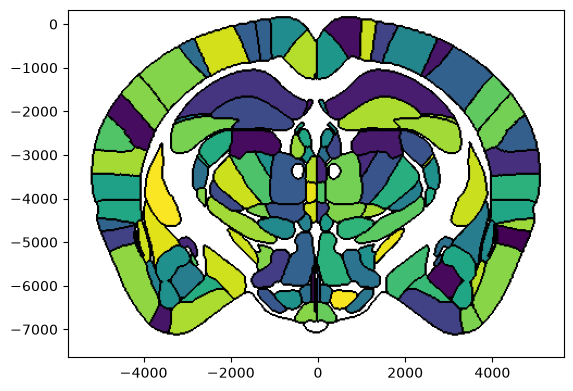

In [3]:
values_lr = np.c_[values_left, values_right]

fig, ax = plot_scalar_on_slice(acronyms, values_lr, coord=-2000, slice='coronal', mapping='Beryl',
                               hemisphere='both', background='boundary', brain_atlas=ba)

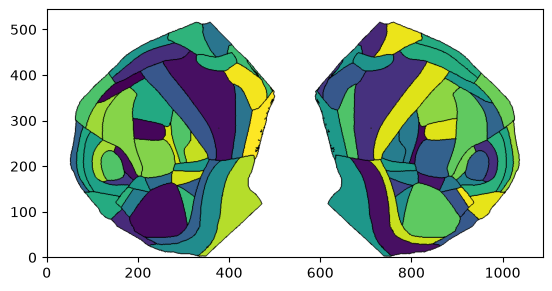

In [4]:
fig, ax = plot_scalar_on_flatmap(acronyms, values_lr, depth=0, mapping='Beryl',
                                 hemisphere='both', background='boundary')

### Values for different regions in each hemisphere

When the two hemispheres have values for different sets of regions, `prepare_lr_data` combines them into one list of acronyms and a two-column array, with NaN where a hemisphere has no value:

In [5]:
acronyms_both, values_both = prepare_lr_data(acronyms[:5], values_left[:5],
                                             acronyms[3:8], values_right[3:8])
print(acronyms_both)
print(values_both.round(2))

['FRP' 'MOp' 'MOs' 'SSp-bfd' 'SSp-ll' 'SSp-m' 'SSp-n' 'SSp-ul']
[[0.64  nan]
 [0.27  nan]
 [0.04  nan]
 [0.81 0.31]
 [ nan 0.42]
 [ nan 0.83]
 [0.02 0.95]
 [ nan 0.41]]


## The Swanson map: signed ids

Convert the acronyms to Allen ids and give the left hemisphere negative ids. With `hemisphere='both'` the map is drawn twice: the right hemisphere, positive ids, at the top, and the left hemisphere, negative ids, at the bottom. See [Tell left from right hemisphere](tell-left-from-right-hemisphere.ipynb) for the negative ids.

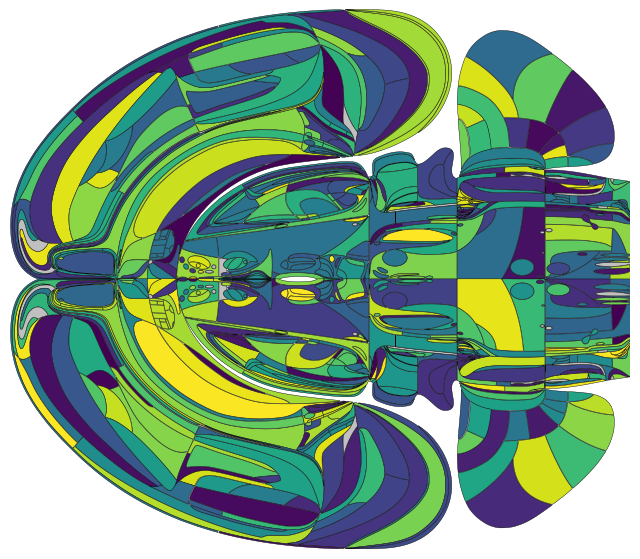

In [6]:
ids = br.acronym2id(acronyms)

fig, ax = plt.subplots(figsize=(8, 8))
plot_swanson_vector(np.r_[ids, -ids], np.r_[values_right, values_left], hemisphere='both',
                    br=br, ax=ax)
ax.axis('off');